In [25]:
# imports
import sys  
from pathlib import Path
from glob import glob
# Get my_package directory path from Notebook
parent_dir = str(Path().resolve().parents[0])
# Add to sys.path
sys.path.insert(0, parent_dir)

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib import cm
from numpy import linalg as LA

from spectral_alignment.utils.common_utils import load_model_config
from scripts.cover_figure_continuous import load_algo_and_env, calculate_SR_heatmap, calculate_Q_heatmap, calculate_wall_mask, add_star_marker, calculate_mean_SR_over_seeds, calculate_mean_Q_over_seeds

In [26]:
# ============================================================
# --- MDP Utils
# ============================================================

def compute_sr(P, gamma):
    """Successor Representation: M = (I - gamma * P)^{-1}"""
    n = P.shape[0]
    return LA.inv(np.eye(n) - gamma * P)

def stable_rank(M):
    """
    Compute the stable rank of matrix M.
    Args:
        M: input matrix (n x n)
    Returns:
        stable_rank: stable rank of M
    """
    frob_norm = LA.norm(M, 'fro')
    op_norm = LA.norm(M, 2)
    return (frob_norm ** 2) / (op_norm ** 2)


def participation_ratio(M, tol=1e-12):
    """
    Participation Ratio of matrix M.

    Parameters
    ----------
    M : np.ndarray
        SR matrix (or approximation)
    tol : float
        Singular values below this are ignored

    Returns
    -------
    float
        Participation ratio
    """
    s = np.linalg.svd(M, compute_uv=False)
    s = s[s > tol]
    s2 = s ** 2

    numerator = np.sum(s2) ** 2
    denominator = np.sum(s2 ** 2)

    if denominator == 0.0:
        return 0.0

    return numerator / denominator


def spectral_entropy(M, tol=1e-12):
    """
    Entropy-based effective rank of matrix M.

    Parameters
    ----------
    M : np.ndarray
        SR matrix (or approximation)
    tol : float
        Singular values below this are ignored

    Returns
    -------
    float
        Entropy effective rank
    """
    s = np.linalg.svd(M, compute_uv=False)
    s = s[s > tol]
    s2 = s ** 2
    p = s2 / np.sum(s2)

    # Numerical safety: avoid log(0)
    entropy = -np.sum(p * np.log(p + 1e-20))
    # Normalize by log(B) where B is the number of components
    # This keeps the metric in the range [0, 1]
    normalization_factor = np.log(len(s))

    return entropy / normalization_factor if normalization_factor > 0 else 0.0

def low_rank_approximation(M, r, use_highest=True):
    """
    Compute the rank-r approximation of matrix M using SVD.
    Args:
        M: input matrix (n x n)
        r: target rank
        use_highest: if True, use top-r singular values; else use bottom-r singular values
    Returns:
        M_r: rank-r approximation of M
    """
    U, S, Vt = LA.svd(M)
    S_r = np.zeros((M.shape[0], M.shape[1]))
    if use_highest:
        S_r[:r, :r] = np.diag(S[:r])
    else:
        S_r[-r:, -r:] = np.diag(S[-r:])
    M_r = U @ S_r @ Vt
    return M_r

def make_four_rooms(rows, cols, wall_thickness=1, door_size=1, border=1):
    free = np.ones((rows, cols), dtype=bool)

    # outer border
    if border > 0:
        free[:border, :] = False
        free[-border:, :] = False
        free[:, :border] = False
        free[:, -border:] = False

    r0, r1 = border, rows - border
    c0, c1 = border, cols - border

    r_mid = (r0 + r1 - 1) // 2
    c_mid = (c0 + c1 - 1) // 2

    # cross walls
    free[r_mid:r_mid + wall_thickness, c0:c1] = False
    free[r0:r1, c_mid:c_mid + wall_thickness] = False

    def clamp(x, lo, hi):
        return int(max(lo, min(hi, x)))

    span_r = r1 - r0
    span_c = c1 - c0

    door_c1 = clamp(c0 + span_c // 3,     c0, c1 - door_size)
    door_c2 = clamp(c0 + 2 * span_c // 3, c0, c1 - door_size)
    door_r1 = clamp(r0 + span_r // 3,     r0, r1 - door_size)
    door_r2 = clamp(r0 + 2 * span_r // 3, r0, r1 - door_size)

    free[r_mid:r_mid + wall_thickness, door_c1:door_c1 + door_size] = True
    free[r_mid:r_mid + wall_thickness, door_c2:door_c2 + door_size] = True
    free[door_r1:door_r1 + door_size, c_mid:c_mid + wall_thickness] = True
    free[door_r2:door_r2 + door_size, c_mid:c_mid + wall_thickness] = True

    return free


# ============================================================
# Transition matrix with walls
# ============================================================
def gridworld_transition_matrix_with_walls(rows, cols, free, stay_prob=0.0):
    N = rows * cols
    P = np.zeros((N, N))

    def idx(r, c): return r * cols + c
    actions = [(-1,0),(1,0),(0,-1),(0,1)]

    for r in range(rows):
        for c in range(cols):
            i = idx(r, c)

            if not free[r, c]:
                P[i, i] = 0.0
                continue

            nbrs = []
            for dr, dc in actions:
                rr, cc = r + dr, c + dc
                if 0 <= rr < rows and 0 <= cc < cols and free[rr, cc]:
                    nbrs.append(idx(rr, cc))

            if not nbrs:
                P[i, i] = 0.0
                continue

            P[i, nbrs] = (1.0 - stay_prob) / len(nbrs)
            P[i, i] += stay_prob

    # make sure rows sum to 1
    row_sums = P.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1.0  # avoid
    P /= row_sums

    return P

def pick_start_state(free, rows, cols, prefer="top_right"):
    candidates = {
        "top_left":     (1, 1),
        "top_right":    (1, cols - 2),
        "bottom_left":  (rows - 2, 1),
        "bottom_right": (rows - 2, cols - 2),
    }
    r, c = candidates.get(prefer, (1, 1))
    if not free[r, c]:
        for rr in range(rows):
            for cc in range(cols):
                if free[rr, cc]:
                    return rr * cols + cc
        raise ValueError("No free cell found.")
    return r * cols + c

In [27]:
# ============================================================
# --- Plotting Utils 
# ============================================================
def plot_sr_on_grid(ax, sr_map, free, s0=None, rows=None, cols=None,
                    title="", vmin=None, vmax=None, grid_lw=0.12,
                    wall_color=(0.9, 0.9, 0.9), ncolors=16, star_size=100):
    masked = np.ma.array(sr_map, mask=~free)

    edges = np.linspace(vmin, vmax, ncolors+1)
    cmap = colors.ListedColormap(cm.Blues(np.linspace(0,1,ncolors)))
    norm = colors.BoundaryNorm(edges, ncolors=ncolors, clip=True)
    # cmap.set_bad(color=(0, 0, 0, 0))  # transparent walls

    ax.set_facecolor(wall_color)

    im = ax.imshow(
        masked,
        cmap=cmap,
        norm=norm,
        interpolation="nearest",
    )

    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])

    # REMOVE black borders (this is the key fix)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.margins(0)

    # lock geometry
    ax.set_aspect("equal")
    ax.set_xlim(-0.5, cols - 0.5)
    ax.set_ylim(rows - 0.5, -0.5)

    # draw borders only around free cells
    for r in range(rows):
        for c in range(cols):
            if free[r, c]:
                rect = plt.Rectangle(
                    (c - 0.5, r - 0.5),
                    1.0, 1.0,
                    fill=False,
                    edgecolor="white",
                    linewidth=grid_lw,
                    zorder=9
                )
                ax.add_patch(rect)

    # start marker
    if s0 is not None:
        r0, c0 = divmod(s0, cols)
        ax.scatter(
            c0, r0,
            marker="*",
            s=star_size,
            c="white",
            edgecolors="black",
            linewidths=1.0,
            zorder=10
        )

    return im
    
def plot_sr_continuous(ax, sr, wall_mask, vmin, vmax, ncolors):
    edges = np.linspace(vmin, vmax, ncolors + 1)
    cmap = colors.ListedColormap(cm.Blues(np.linspace(0, 1, ncolors)))
    norm = colors.BoundaryNorm(edges, ncolors=ncolors, clip=True)
    
    ax.set_facecolor((0.9, 0.9, 0.9))  # set background color for walls
    SR_masked = np.ma.array(sr, mask=wall_mask)  # mask walls so they appear as light gray
    ax.imshow(SR_masked, cmap=cmap, norm=norm)
    ax.spines[["right", "top", "left", "bottom"]].set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])  

# COVER FIGURE (Discrete and Continuous together) -- SR

In [28]:
# ============================================================
# --- Discrete MDP Calculations ---
# ============================================================

GRID_ROWS = GRID_COLS = 20
Ks = [1, 5, 9, 11]
GAMMAS = [0.9, 0.95, 0.99, 0.999]
MIXING    = 0.8
REWARD = 1.0
MAX_RANK = 4

# --- Create MDP ---
free = make_four_rooms(GRID_ROWS, GRID_COLS, border=1)
P = gridworld_transition_matrix_with_walls(rows=GRID_ROWS, cols=GRID_COLS, free=free, stay_prob=1.0 - MIXING)

# --- Define Start (SR), Goal (V), and Reward (V) ---
r_start, c_start = 4, 4
s0 = g0 = r_start * GRID_COLS + c_start
sparse_rew_vector = np.zeros(GRID_ROWS * GRID_COLS)
sparse_rew_vector[g0] = REWARD
assert free[r_start, c_start]

# ============================================================
# Compute SR and V maps for all (gamma, K)
# ============================================================
sr_maps = {}  # sr_maps[(gamma, K)] = (GRID_ROWS, GRID_COLS)
q_maps = {}   # v_maps[(gamma, K)] = (GRID_ROWS, GRID_COLS) # for value function
low_rank_sr_maps = {}
low_rank_q_maps = {}
for gamma in GAMMAS:
    # K = 1
    M1 = compute_sr(P, gamma)
    LR_M1 = low_rank_approximation(M1, MAX_RANK, use_highest=True)
    sr_maps[(gamma, 1)] = M1[s0].reshape(GRID_ROWS, GRID_COLS)
    q_maps[(gamma, 1)] = np.matmul(M1, sparse_rew_vector).reshape(GRID_ROWS, GRID_COLS)
    low_rank_sr_maps[(gamma, 1)] = LR_M1[s0].reshape(GRID_ROWS, GRID_COLS)
    low_rank_q_maps[(gamma, 1)] = np.matmul(LR_M1, sparse_rew_vector).reshape(GRID_ROWS, GRID_COLS)

    # K > 1
    for K in Ks:
        if K == 1:
            continue
        PK = np.linalg.matrix_power(P, K)
        MK = compute_sr(PK, gamma)
        LR_MK = low_rank_approximation(MK, MAX_RANK, use_highest=True)
        sr_maps[(gamma, K)] = MK[s0].reshape(GRID_ROWS, GRID_COLS)
        q_maps[(gamma, K)] = np.matmul(MK, sparse_rew_vector).reshape(GRID_ROWS, GRID_COLS)
        low_rank_sr_maps[(gamma, K)] = LR_MK[s0].reshape(GRID_ROWS, GRID_COLS)
        low_rank_q_maps[(gamma, K)] = np.matmul(LR_MK, sparse_rew_vector).reshape(GRID_ROWS, GRID_COLS)
        
# ============================================================
# --- Continuous MDP Calculations ---
# ============================================================
EXPERIMENTS = {"baseline": "../models/FBRL/RoomsEnv/rbf__act-rep-1__gamma-0.95__zdim-100", 
              "low_rank": "../models/FBRL/RoomsEnv/rbf__act-rep-1__gamma-0.95__zdim-25",
              "high_gamma": "../models/FBRL/RoomsEnv/rbf__act-rep-1__gamma-0.999__zdim-100",
              "high_k": "../models/FBRL/RoomsEnv/rbf__act-rep-10__gamma-0.95__zdim-100" }
EXAMPLE_MODEL_PATH = glob(str(Path(EXPERIMENTS["baseline"])/ "seed_*" / "**" / "model_top_1.zip"))[0]
RESOLUTION = 100
START = GOAL = (2, 2)
STAR_START_GOAL = (6,2) # plotting weirdness not worth fixing right now
STAR_OFFSET = [0.0, 0.0]
PLOT_SAVE_PATH = Path("plots/cover_figure")
PLOT_SAVE_PATH.mkdir(parents=True, exist_ok=True)
# Plotting
NCOLORS = 32
QUANTILE_LOW = 0.0
QUANTILE_HIGH = 0.99
STAR_SIZE = 100
_, env = load_algo_and_env(model_path=EXAMPLE_MODEL_PATH)
wall_mask = calculate_wall_mask(env, resolution=RESOLUTION)

2026-11-03 13:52:08 rescale1 matplotlib.backends.backend_pdf[1452744] DEBUG Assigning font /F1 (subset 0) = FontPath('/home/basiri/Dev/spectral_alignment/.venv/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf', 0)
2026-11-03 13:52:08 rescale1 matplotlib.backends.backend_pdf[1452744] DEBUG Assigning font /F2 (subset 1) = FontPath('/home/basiri/Dev/spectral_alignment/.venv/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans-Oblique.ttf', 0)
2026-11-03 13:52:09 rescale1 matplotlib.backends.backend_pdf[1452744] DEBUG Embedding font FontPath('/home/basiri/Dev/spectral_alignment/.venv/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans-Oblique.ttf', 0):1.
2026-11-03 13:52:09 rescale1 matplotlib.backends.backend_pdf[1452744] DEBUG Writing TrueType font.
2026-11-03 13:52:09 rescale1 matplotlib.backends.backend_pdf[1452744] DEBUG Embedding font FontPath('/home/basiri/Dev/spectral_alignment/.venv/lib/python3.11/site-packages/matplotlib

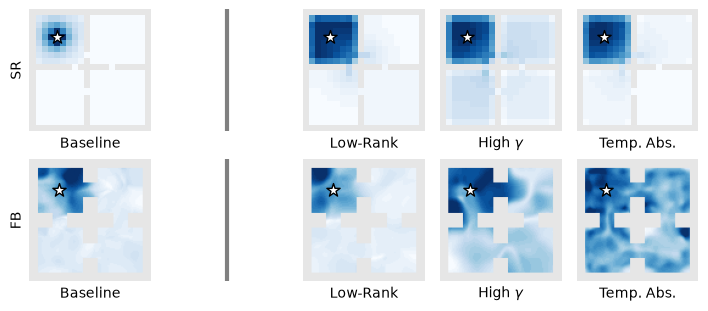

In [29]:
# ============================================================
# Plot: Discrete MDP --- SR
# ============================================================
fig_rows, fig_cols = 2, 5
fig, axes = plt.subplots(fig_rows, fig_cols, figsize=(7, 3), constrained_layout=True)

# --- K=1, Gamma=0.9, No SVD ---
vals = sr_maps[(0.95, 1)][free].ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_on_grid(axes[0,0], sr_maps[(0.95, 1)], free, s0=s0, rows=GRID_ROWS, cols=GRID_COLS, title="", vmin=vmin, vmax=vmax, ncolors=NCOLORS, grid_lw=0.0, star_size=STAR_SIZE)
axes[0,0].set_xlabel("Baseline")
axes[0,0].set_ylabel("SR")

# --- separation ---
axes[0,1].set_xticks([])
axes[0,1].set_yticks([])
axes[0,1].spines[["top", "right", "bottom", "left"]].set_visible(False)
axes[0,1].axvline(x=0.5, ymin=0.0, ymax=1.0, c="gray", linewidth=3)

# --- SVD(K=1, Gamma=0.9) ---
vals = low_rank_sr_maps[(0.95, 1)][free].ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_on_grid(axes[0,2], low_rank_sr_maps[(0.95, 1)], free, s0=s0, rows=GRID_ROWS, cols=GRID_COLS, title="", vmin=vmin, vmax=vmax, ncolors=NCOLORS, grid_lw=0.0, star_size=STAR_SIZE)
axes[0,2].set_xlabel("Low-Rank")

# --- K=1, Gamma=0.99, No SVD ---
vals = sr_maps[(0.999, 1)][free].ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_on_grid(axes[0,3], sr_maps[(0.999, 1)], free, s0=s0, rows=GRID_ROWS, cols=GRID_COLS, title="", vmin=vmin, vmax=vmax, ncolors=NCOLORS, grid_lw=0.0, star_size=STAR_SIZE)
axes[0,3].set_xlabel("High $\gamma$")

# --- K=9, Gamma=0.9, No SVD ---
vals = sr_maps[(0.95, 9)][free].ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_on_grid(axes[0,4], sr_maps[(0.95, 9)], free, s0=s0, rows=GRID_ROWS, cols=GRID_COLS, title="", vmin=vmin, vmax=vmax, ncolors=NCOLORS, grid_lw=0.0, star_size=STAR_SIZE)
axes[0,4].set_xlabel("Temp. Abs.")


# ============================================================
# Plot: Continuous MDP --- SR
# ============================================================
# --- baseline ---
SR = calculate_mean_SR_over_seeds(EXPERIMENTS["baseline"], resolution=RESOLUTION, start_ij=START)

vals = SR.ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_continuous(ax=axes[1,0], sr=SR, wall_mask=wall_mask, vmin=vmin, vmax=vmax, ncolors=NCOLORS)
add_star_marker(axes[1,0], STAR_START_GOAL, env, RESOLUTION, size=STAR_SIZE,offset=STAR_OFFSET)
axes[1, 0].set_xlabel("Baseline")
axes[1, 0].set_ylabel("FB")

# --- separation ---
axes[1,1].set_xticks([])
axes[1,1].set_yticks([])
axes[1,1].spines[["top", "right", "bottom", "left"]].set_visible(False)
axes[1,1].axvline(x=0.5, ymin=0.0, ymax=1.0, c="gray", linewidth=3)

# --- Low-Rank ---
SR = calculate_mean_SR_over_seeds(EXPERIMENTS["low_rank"], resolution=RESOLUTION, start_ij=START)

vals = SR.ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_continuous(ax=axes[1,2], sr=SR, wall_mask=wall_mask, vmin=vmin, vmax=vmax, ncolors=NCOLORS)
add_star_marker(axes[1,2], STAR_START_GOAL, env, RESOLUTION, size=STAR_SIZE,offset=STAR_OFFSET)
axes[1,2].set_xlabel("Low-Rank")

# --- high-gamma ---
SR = calculate_mean_SR_over_seeds(EXPERIMENTS["high_gamma"], resolution=RESOLUTION, start_ij=START)

vals = SR.ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_continuous(ax=axes[1,3], sr=SR, wall_mask=wall_mask, vmin=vmin, vmax=vmax, ncolors=NCOLORS)
add_star_marker(axes[1,3], STAR_START_GOAL, env, RESOLUTION, size=STAR_SIZE,offset=STAR_OFFSET)
axes[1,3].set_xlabel("High $\gamma$")

# --- high-k ---
SR = calculate_mean_SR_over_seeds(EXPERIMENTS["high_k"], resolution=RESOLUTION, start_ij=START)

vals = SR.ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_continuous(ax=axes[1,4], sr=SR, wall_mask=wall_mask, vmin=vmin, vmax=vmax, ncolors=NCOLORS)
add_star_marker(axes[1,4], STAR_START_GOAL, env, RESOLUTION, size=STAR_SIZE,offset=STAR_OFFSET)
axes[1,4].set_xlabel("Temp. Abs.")



# fig.suptitle("Three Paths to Low-Rank SR")
fig.savefig(PLOT_SAVE_PATH / "three_paths_sr_disc_cont.pdf")
plt.show()

2026-11-03 13:52:12 rescale1 matplotlib.backends.backend_pdf[1452744] DEBUG Assigning font /F1 (subset 0) = FontPath('/home/basiri/Dev/spectral_alignment/.venv/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf', 0)
2026-11-03 13:52:12 rescale1 matplotlib.backends.backend_pdf[1452744] DEBUG Assigning font /F2 (subset 0) = FontPath('/home/basiri/Dev/spectral_alignment/.venv/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans-Oblique.ttf', 0)
2026-11-03 13:52:12 rescale1 matplotlib.backends.backend_pdf[1452744] DEBUG Assigning font /F3 (subset 1) = FontPath('/home/basiri/Dev/spectral_alignment/.venv/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans-Oblique.ttf', 0)
2026-11-03 13:52:12 rescale1 matplotlib.backends.backend_pdf[1452744] DEBUG Embedding font FontPath('/home/basiri/Dev/spectral_alignment/.venv/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans-Oblique.ttf', 0):0.
2026-11-03 13:52:12 rescale1 matpl

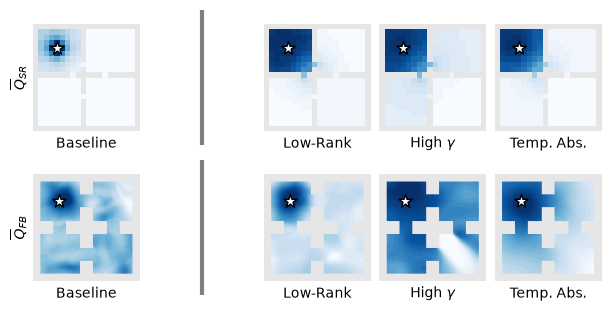

In [30]:
# ============================================================
# Plot: Discrete MDP --- Q
# ============================================================
fig_rows, fig_cols = 2, 5
fig, axes = plt.subplots(fig_rows, fig_cols, figsize=(6, 3), constrained_layout=True)

# --- K=1, Gamma=0.9, No SVD ---
vals = q_maps[(0.95, 1)][free].ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_on_grid(axes[0,0], q_maps[(0.95, 1)], free, s0=s0, rows=GRID_ROWS, cols=GRID_COLS, title="", vmin=vmin, vmax=vmax, ncolors=NCOLORS, grid_lw=0.0, star_size=STAR_SIZE)
axes[0,0].set_xlabel("Baseline")
axes[0,0].set_ylabel("$\overline{Q}_{SR}$")

# --- separation ---
axes[0,1].set_xticks([])
axes[0,1].set_yticks([])
axes[0,1].spines[["top", "right", "bottom", "left"]].set_visible(False)
axes[0,1].axvline(x=0.5, ymin=0.0, ymax=1.0, c="gray", linewidth=3)

# --- SVD(K=1, Gamma=0.9) ---
vals = low_rank_q_maps[(0.95, 1)][free].ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_on_grid(axes[0,2], low_rank_q_maps[(0.95, 1)], free, s0=s0, rows=GRID_ROWS, cols=GRID_COLS, title="", vmin=vmin, vmax=vmax, ncolors=NCOLORS, grid_lw=0.0, star_size=STAR_SIZE)
axes[0,2].set_xlabel("Low-Rank")

# --- K=1, Gamma=0.99, No SVD ---
vals = q_maps[(0.999, 1)][free].ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_on_grid(axes[0,3], q_maps[(0.999, 1)], free, s0=s0, rows=GRID_ROWS, cols=GRID_COLS, title="", vmin=vmin, vmax=vmax, ncolors=NCOLORS, grid_lw=0.0, star_size=STAR_SIZE)
axes[0,3].set_xlabel("High $\gamma$")

# --- K=9, Gamma=0.9, No SVD ---
vals = q_maps[(0.95, 9)][free].ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_on_grid(axes[0,4], q_maps[(0.95, 9)], free, s0=s0, rows=GRID_ROWS, cols=GRID_COLS, title="", vmin=vmin, vmax=vmax, ncolors=NCOLORS, grid_lw=0.0, star_size=STAR_SIZE)
axes[0,4].set_xlabel("Temp. Abs.")


# ============================================================
# Plot: Continuous MDP --- Q
# ============================================================
# --- baseline ---
Q = calculate_mean_Q_over_seeds(EXPERIMENTS["baseline"], resolution=RESOLUTION, goal_ij=GOAL)

vals = Q.ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_continuous(ax=axes[1,0], sr=Q, wall_mask=wall_mask, vmin=vmin, vmax=vmax, ncolors=NCOLORS)
add_star_marker(axes[1,0], STAR_START_GOAL, env, RESOLUTION, size=STAR_SIZE,offset=STAR_OFFSET)
axes[1,0].set_xlabel("Baseline")
axes[1,0].set_ylabel("$\overline{Q}_{FB}$")

# --- separation --- 
axes[1,1].set_xticks([])
axes[1,1].set_yticks([])
axes[1,1].spines[["top", "right", "bottom", "left"]].set_visible(False)
axes[1,1].axvline(x=0.5, ymin=0.0, ymax=1.0, c="gray", linewidth=3)

# --- Low-Rank ---
Q = calculate_mean_Q_over_seeds(EXPERIMENTS["low_rank"], resolution=RESOLUTION, goal_ij=GOAL)

vals = Q.ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_continuous(ax=axes[1,2], sr=Q, wall_mask=wall_mask, vmin=vmin, vmax=vmax, ncolors=NCOLORS)
add_star_marker(axes[1,2], STAR_START_GOAL, env, RESOLUTION, size=STAR_SIZE,offset=STAR_OFFSET)
axes[1,2].set_xlabel("Low-Rank")

# --- high-gamma ---
Q = calculate_mean_Q_over_seeds(EXPERIMENTS["high_gamma"], resolution=RESOLUTION, goal_ij=GOAL)

vals = Q.ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_continuous(ax=axes[1,3], sr=Q, wall_mask=wall_mask, vmin=vmin, vmax=vmax, ncolors=NCOLORS)
add_star_marker(axes[1,3], STAR_START_GOAL, env, RESOLUTION, size=STAR_SIZE,offset=STAR_OFFSET)
axes[1,3].set_xlabel("High $\gamma$")

# --- high-k ---
Q = calculate_mean_Q_over_seeds(EXPERIMENTS["high_k"], resolution=RESOLUTION, goal_ij=GOAL)

vals = Q.ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_continuous(ax=axes[1,4], sr=Q, wall_mask=wall_mask, vmin=vmin, vmax=vmax, ncolors=NCOLORS)
add_star_marker(axes[1,4], STAR_START_GOAL, env, RESOLUTION, size=STAR_SIZE,offset=STAR_OFFSET)
axes[1,4].set_xlabel("Temp. Abs.")



# fig.suptitle("Three Paths to Low-Rank Q")
fig.savefig(PLOT_SAVE_PATH/"three_paths_q_disc_cont.pdf")
plt.show()

# Cover Figure 2 -- SR and Q both

2026-11-03 13:52:18 rescale1 matplotlib.backends.backend_pdf[1452744] DEBUG Assigning font /F1 (subset 0) = FontPath('/home/basiri/Dev/spectral_alignment/.venv/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf', 0)
2026-11-03 13:52:18 rescale1 matplotlib.backends.backend_pdf[1452744] DEBUG Assigning font /F2 (subset 1) = FontPath('/home/basiri/Dev/spectral_alignment/.venv/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans-Oblique.ttf', 0)
2026-11-03 13:52:18 rescale1 matplotlib.backends.backend_pdf[1452744] DEBUG Assigning font /F3 (subset 0) = FontPath('/home/basiri/Dev/spectral_alignment/.venv/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans-Oblique.ttf', 0)
2026-11-03 13:52:18 rescale1 matplotlib.backends.backend_pdf[1452744] DEBUG Embedding font FontPath('/home/basiri/Dev/spectral_alignment/.venv/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans-Oblique.ttf', 0):0.
2026-11-03 13:52:18 rescale1 matpl

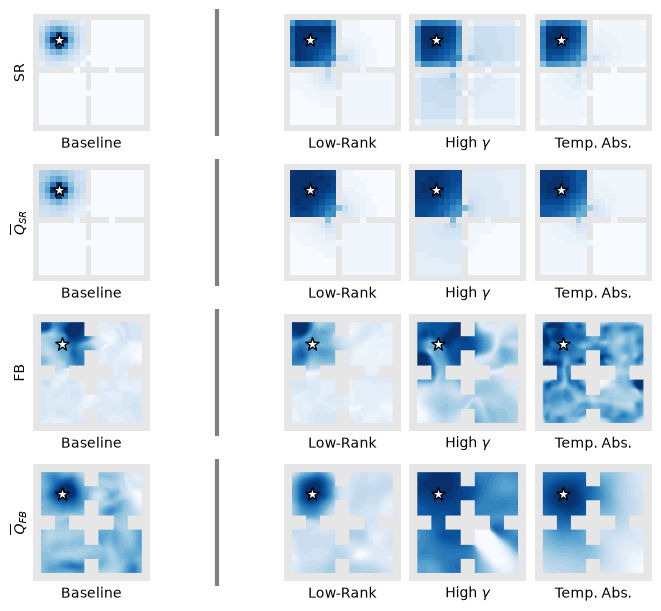

In [31]:
fig_rows, fig_cols = 4, 5
fig, axes = plt.subplots(fig_rows, fig_cols, figsize=(6.5, 6), constrained_layout=True)
# ============================================================
# Plot: Discrete MDP --- SR
# ============================================================
# --- K=1, Gamma=0.9, No SVD ---
vals = sr_maps[(0.95, 1)][free].ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_on_grid(axes[0,0], sr_maps[(0.95, 1)], free, s0=s0, rows=GRID_ROWS, cols=GRID_COLS, title="", vmin=vmin, vmax=vmax, ncolors=NCOLORS, grid_lw=0.0, star_size=STAR_SIZE)
axes[0,0].set_xlabel("Baseline")
axes[0,0].set_ylabel("SR")

# --- separation ---
axes[0,1].set_xticks([])
axes[0,1].set_yticks([])
axes[0,1].spines[["top", "right", "bottom", "left"]].set_visible(False)
axes[0,1].axvline(x=0.5, ymin=0.0, ymax=1.0, c="gray", linewidth=3)

# --- SVD(K=1, Gamma=0.9) ---
vals = low_rank_sr_maps[(0.95, 1)][free].ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_on_grid(axes[0,2], low_rank_sr_maps[(0.95, 1)], free, s0=s0, rows=GRID_ROWS, cols=GRID_COLS, title="", vmin=vmin, vmax=vmax, ncolors=NCOLORS, grid_lw=0.0, star_size=STAR_SIZE)
axes[0,2].set_xlabel("Low-Rank")

# --- K=1, Gamma=0.99, No SVD ---
vals = sr_maps[(0.999, 1)][free].ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_on_grid(axes[0,3], sr_maps[(0.999, 1)], free, s0=s0, rows=GRID_ROWS, cols=GRID_COLS, title="", vmin=vmin, vmax=vmax, ncolors=NCOLORS, grid_lw=0.0, star_size=STAR_SIZE)
axes[0,3].set_xlabel("High $\gamma$")

# --- K=9, Gamma=0.9, No SVD ---
vals = sr_maps[(0.95, 9)][free].ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_on_grid(axes[0,4], sr_maps[(0.95, 9)], free, s0=s0, rows=GRID_ROWS, cols=GRID_COLS, title="", vmin=vmin, vmax=vmax, ncolors=NCOLORS, grid_lw=0.0, star_size=STAR_SIZE)
axes[0,4].set_xlabel("Temp. Abs.")

# ============================================================
# Plot: Discrete MDP --- Q
# ============================================================

# --- K=1, Gamma=0.9, No SVD ---
vals = q_maps[(0.95, 1)][free].ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_on_grid(axes[1,0], q_maps[(0.95, 1)], free, s0=s0, rows=GRID_ROWS, cols=GRID_COLS, title="", vmin=vmin, vmax=vmax, ncolors=NCOLORS, grid_lw=0.0, star_size=STAR_SIZE)
axes[1,0].set_xlabel("Baseline")
axes[1,0].set_ylabel("$\overline{Q}_{SR}$")

# --- separation ---
axes[1,1].set_xticks([])
axes[1,1].set_yticks([])
axes[1,1].spines[["top", "right", "bottom", "left"]].set_visible(False)
axes[1,1].axvline(x=0.5, ymin=0.0, ymax=1.0, c="gray", linewidth=3)

# --- SVD(K=1, Gamma=0.9) ---
vals = low_rank_q_maps[(0.95, 1)][free].ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_on_grid(axes[1,2], low_rank_q_maps[(0.95, 1)], free, s0=s0, rows=GRID_ROWS, cols=GRID_COLS, title="", vmin=vmin, vmax=vmax, ncolors=NCOLORS, grid_lw=0.0, star_size=STAR_SIZE)
axes[1,2].set_xlabel("Low-Rank")

# --- K=1, Gamma=0.99, No SVD ---
vals = q_maps[(0.999, 1)][free].ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_on_grid(axes[1,3], q_maps[(0.999, 1)], free, s0=s0, rows=GRID_ROWS, cols=GRID_COLS, title="", vmin=vmin, vmax=vmax, ncolors=NCOLORS, grid_lw=0.0, star_size=STAR_SIZE)
axes[1,3].set_xlabel("High $\gamma$")

# --- K=9, Gamma=0.9, No SVD ---
vals = q_maps[(0.95, 9)][free].ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_on_grid(axes[1,4], q_maps[(0.95, 9)], free, s0=s0, rows=GRID_ROWS, cols=GRID_COLS, title="", vmin=vmin, vmax=vmax, ncolors=NCOLORS, grid_lw=0.0, star_size=STAR_SIZE)
axes[1,4].set_xlabel("Temp. Abs.")

# ============================================================
# Plot: Continuous MDP --- SR
# ============================================================
# --- baseline ---
SR = calculate_mean_SR_over_seeds(EXPERIMENTS["baseline"], resolution=RESOLUTION, start_ij=START)

vals = SR.ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_continuous(ax=axes[2,0], sr=SR, wall_mask=wall_mask, vmin=vmin, vmax=vmax, ncolors=NCOLORS)
add_star_marker(axes[2,0], STAR_START_GOAL, env, RESOLUTION, size=STAR_SIZE,offset=STAR_OFFSET)
axes[2, 0].set_xlabel("Baseline")
axes[2,0].set_ylabel("FB")

# --- separation ---
axes[2,1].set_xticks([])
axes[2,1].set_yticks([])
axes[2,1].spines[["top", "right", "bottom", "left"]].set_visible(False)
axes[2,1].axvline(x=0.5, ymin=0.0, ymax=1.0, c="gray", linewidth=3)

# --- Low-Rank ---
SR = calculate_mean_SR_over_seeds(EXPERIMENTS["low_rank"], resolution=RESOLUTION, start_ij=START)

vals = SR.ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_continuous(ax=axes[2,2], sr=SR, wall_mask=wall_mask, vmin=vmin, vmax=vmax, ncolors=NCOLORS)
add_star_marker(axes[2,2], STAR_START_GOAL, env, RESOLUTION, size=STAR_SIZE,offset=STAR_OFFSET)
axes[2,2].set_xlabel("Low-Rank")

# --- high-gamma ---
SR = calculate_mean_SR_over_seeds(EXPERIMENTS["high_gamma"], resolution=RESOLUTION, start_ij=START)

vals = SR.ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_continuous(ax=axes[2,3], sr=SR, wall_mask=wall_mask, vmin=vmin, vmax=vmax, ncolors=NCOLORS)
add_star_marker(axes[2,3], STAR_START_GOAL, env, RESOLUTION, size=STAR_SIZE,offset=STAR_OFFSET)
axes[2,3].set_xlabel("High $\gamma$")

# --- high-k ---
SR = calculate_mean_SR_over_seeds(EXPERIMENTS["high_k"], resolution=RESOLUTION, start_ij=START)

vals = SR.ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_continuous(ax=axes[2,4], sr=SR, wall_mask=wall_mask, vmin=vmin, vmax=vmax, ncolors=NCOLORS)
add_star_marker(axes[2,4], STAR_START_GOAL, env, RESOLUTION, size=STAR_SIZE,offset=STAR_OFFSET)
axes[2,4].set_xlabel("Temp. Abs.")



# ============================================================
# Plot: Continuous MDP --- Q
# ============================================================
# --- baseline ---
Q = calculate_mean_Q_over_seeds(EXPERIMENTS["baseline"], resolution=RESOLUTION, goal_ij=GOAL)

vals = Q.ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_continuous(ax=axes[3,0], sr=Q, wall_mask=wall_mask, vmin=vmin, vmax=vmax, ncolors=NCOLORS)
add_star_marker(axes[3,0], STAR_START_GOAL, env, RESOLUTION, size=STAR_SIZE,offset=STAR_OFFSET)
axes[3,0].set_xlabel("Baseline")
axes[3,0].set_ylabel("$\overline{Q}_{FB}$")

# --- separation ---
axes[3,1].set_xticks([])
axes[3,1].set_yticks([])
axes[3,1].spines[["top", "right", "bottom", "left"]].set_visible(False)
axes[3,1].axvline(x=0.5, ymin=0.0, ymax=1.0, c="gray", linewidth=3)

# --- Low-Rank ---
Q = calculate_mean_Q_over_seeds(EXPERIMENTS["low_rank"], resolution=RESOLUTION, goal_ij=GOAL)

vals = Q.ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_continuous(ax=axes[3,2], sr=Q, wall_mask=wall_mask, vmin=vmin, vmax=vmax, ncolors=NCOLORS)
add_star_marker(axes[3,2], STAR_START_GOAL, env, RESOLUTION, size=STAR_SIZE,offset=STAR_OFFSET)
axes[3,2].set_xlabel("Low-Rank")

# --- high-gamma ---
Q = calculate_mean_Q_over_seeds(EXPERIMENTS["high_gamma"], resolution=RESOLUTION, goal_ij=GOAL)

vals = Q.ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_continuous(ax=axes[3,3], sr=Q, wall_mask=wall_mask, vmin=vmin, vmax=vmax, ncolors=NCOLORS)
add_star_marker(axes[3,3], STAR_START_GOAL, env, RESOLUTION, size=STAR_SIZE,offset=STAR_OFFSET)
axes[3,3].set_xlabel("High $\gamma$")

# --- high-k ---
Q = calculate_mean_Q_over_seeds(EXPERIMENTS["high_k"], resolution=RESOLUTION, goal_ij=GOAL)

vals = Q.ravel()
vmin, vmax = np.quantile(vals, [QUANTILE_LOW, QUANTILE_HIGH])
plot_sr_continuous(ax=axes[3,4], sr=Q, wall_mask=wall_mask, vmin=vmin, vmax=vmax, ncolors=NCOLORS)
add_star_marker(axes[3,4], STAR_START_GOAL, env, RESOLUTION, size=STAR_SIZE,offset=STAR_OFFSET)
axes[3,4].set_xlabel("Temp. Abs.")



# fig.suptitle("Three Paths to Low-Rankness")
fig.savefig(PLOT_SAVE_PATH /"three_paths_all.pdf")
plt.show()

# Website -- Q and SR for every action repeat k and every goal / start cell
Exports the data for the interactive explorer in `docs/` (`docs/assets/heatmaps.js`) plus static PNGs of the default goal in `plots/website/`.

- k in `WEB_KS`; the discrete maps use the k-step chain $P^k$, the continuous ones the trained FB model with action repeat k.
- Every free cell is precomputed as a goal (for Q) and as a start (for SR), so the page can switch goals on click.
- Each map is clipped to its own [QUANTILE_LOW, QUANTILE_HIGH] range (as in the cover figure) and stored as uint8 (0-254, 255 = wall), so the page shows how the *shape* changes with k, not the scale.
- Continuous maps are transposed to (row = i, col = j) of `maze_map`; the cover-figure cells above plot them transposed, which is invisible only because four rooms is symmetric.

In [32]:
import json
import base64

WEB_KS = [1, 3, 5, 10, 20]
WEB_GAMMA = 0.95
WEB_RESOLUTION = 64  # continuous maps on the website (the PNGs use RESOLUTION)
WEB_SAVE_PATH = Path("plots/website")
WEB_SAVE_PATH.mkdir(parents=True, exist_ok=True)
# a script (not .json) so the page also works when index.html is opened from disk (file:// blocks fetch)
DOCS_DATA_PATH = Path("../docs/assets/heatmaps.js")
DOCS_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)

def to_uint8_b64(m, valid):
    # clip to the same quantile range as the cover figure, scale to 0..254; 255 marks walls
    vmin, vmax = np.quantile(m[valid], [QUANTILE_LOW, QUANTILE_HIGH])
    out = np.round(np.clip((m - vmin) / (vmax - vmin + 1e-12), 0.0, 1.0) * 254).astype(np.uint8)
    out[~valid] = 255
    return base64.b64encode(out.tobytes()).decode()

def save_panel(m, path, continuous):
    fig, ax = plt.subplots(figsize=(3, 3))
    if continuous:
        vmin, vmax = np.quantile(m[~wall_mask], [QUANTILE_LOW, QUANTILE_HIGH])
        plot_sr_continuous(ax=ax, sr=m, wall_mask=wall_mask, vmin=vmin, vmax=vmax, ncolors=NCOLORS)
        add_star_marker(ax, STAR_START_GOAL, env, RESOLUTION, size=STAR_SIZE, offset=STAR_OFFSET)
    else:
        vmin, vmax = np.quantile(m[free], [QUANTILE_LOW, QUANTILE_HIGH])
        plot_sr_on_grid(ax, m, free, s0=s0, rows=GRID_ROWS, cols=GRID_COLS, vmin=vmin, vmax=vmax, ncolors=NCOLORS, grid_lw=0.0, star_size=STAR_SIZE)
    fig.savefig(path, dpi=150, bbox_inches="tight", pad_inches=0)
    plt.close(fig)

# --- clickable cells ---
# continuous: centers of the free maze cells; the heatmap grid spans cell center (0, 0) to (n-1, n-1),
# so cell (i, j) sits at map pixel (i, j) * (WEB_RESOLUTION - 1) / (n - 1)
maze_map = env.unwrapped.maze_map
n_maze = maze_map.shape[0]
cont_cells = [(i, j) for i in range(n_maze) for j in range(n_maze) if maze_map[i, j] == 0]
cont_px = [[i * (WEB_RESOLUTION - 1) / (n_maze - 1), j * (WEB_RESOLUTION - 1) / (n_maze - 1)] for i, j in cont_cells]
web_free = ~calculate_wall_mask(env, resolution=WEB_RESOLUTION)  # (row = i, col = j)
# discrete: every free cell of the grid world
disc_cells = [(r, c) for r in range(GRID_ROWS) for c in range(GRID_COLS) if free[r, c]]

web_data = {
    "ks": WEB_KS,
    "gamma": WEB_GAMMA,
    "test_return": {},
    "continuous": {"res": WEB_RESOLUTION, "cells": cont_px, "default": cont_cells.index(tuple(START)), "maps": {}},
    "discrete": {"res": GRID_ROWS, "cells": [[r, c] for r, c in disc_cells], "default": disc_cells.index((r_start, c_start)), "maps": {}},
}

for K in WEB_KS:
    exp_path = f"../models/FBRL/RoomsEnv/rbf__act-rep-{K}__gamma-{WEB_GAMMA}__zdim-100"
    model_paths = glob(f"{exp_path}/seed_*/**/model_top_1.zip", recursive=True)
    algos = [load_algo_and_env(p)[0] for p in model_paths]

    # --- continuous (trained FB models, mean over seeds), transposed to (row = i, col = j) ---
    q_list, sr_list = [], []
    for ij in cont_cells:
        Q = np.mean([calculate_Q_heatmap(env, a, resolution=WEB_RESOLUTION, goal_ij=ij) for a in algos], axis=0).T
        SR = np.mean([calculate_SR_heatmap(env, a, resolution=WEB_RESOLUTION, start_ij=ij) for a in algos], axis=0).T
        q_list.append(to_uint8_b64(Q, web_free))
        sr_list.append(to_uint8_b64(SR, web_free))
    web_data["continuous"]["maps"][K] = {"q": q_list, "sr": sr_list}

    # --- discrete (closed form): SR of the k-step chain, M_k = (I - gamma P^k)^{-1} ---
    # Q for goal g is column g of M_k (reward 1 at g), SR from start s is row s
    MK = compute_sr(np.linalg.matrix_power(P, K), WEB_GAMMA)
    web_data["discrete"]["maps"][K] = {
        "q": [to_uint8_b64(MK[:, r * GRID_COLS + c].reshape(GRID_ROWS, GRID_COLS), free) for r, c in disc_cells],
        "sr": [to_uint8_b64(MK[r * GRID_COLS + c].reshape(GRID_ROWS, GRID_COLS), free) for r, c in disc_cells],
    }

    # --- static PNGs for the default goal / start ---
    save_panel(calculate_mean_SR_over_seeds(exp_path, resolution=RESOLUTION, start_ij=START), WEB_SAVE_PATH / f"fb_sr_k{K}.png", continuous=True)
    save_panel(calculate_mean_Q_over_seeds(exp_path, resolution=RESOLUTION, goal_ij=GOAL), WEB_SAVE_PATH / f"fb_q_k{K}.png", continuous=True)
    save_panel(MK[s0].reshape(GRID_ROWS, GRID_COLS), WEB_SAVE_PATH / f"disc_sr_k{K}.png", continuous=False)
    save_panel((MK @ sparse_rew_vector).reshape(GRID_ROWS, GRID_COLS), WEB_SAVE_PATH / f"disc_q_k{K}.png", continuous=False)

    # --- success rate of the same models (scripts/evaluate_all_fbrl_models.py) ---
    test_files = glob(f"{exp_path}/seed_*/**/test_evaluations__model_top_1.npz", recursive=True)
    if test_files:
        web_data["test_return"][K] = float(np.mean([np.load(f)["returns"].mean() for f in test_files]))

with open(DOCS_DATA_PATH, "w") as f:
    f.write("// generated by notebooks/cover_figure.ipynb -- do not edit\n")
    f.write("window.HEATMAP_DATA = " + json.dumps(web_data, separators=(",", ":")) + ";\n")
print(f"{len(cont_cells)} continuous / {len(disc_cells)} discrete cells, {DOCS_DATA_PATH.stat().st_size / 1e6:.1f} MB -> {DOCS_DATA_PATH}")
print("test return per k:", web_data["test_return"])

40 continuous / 293 discrete cells, 3.8 MB -> ../docs/assets/heatmaps.js
test return per k: {1: 0.08, 3: 0.54, 5: 0.8, 10: 0.96, 20: 0.92}


# Website -- spectrum of the SR as a function of k
Exports the data for the spectrum widget in `docs/` (`docs/assets/spectrum_data.js`). Discrete four rooms only, no GPU needed.

- $M_k = (I - \gamma P^k)^{-1}$ has the eigenvectors of $P$ for every $k$, with eigenvalues $\mu_i(k) = 1 / (1 - \gamma \lambda_i^k)$, so the page computes $\mu(k)$ itself from $\lambda$ and the slider is not limited to trained values of k.
- Eigenvectors are sorted by $\lambda_i$ of $P$ (index = frequency), so the order stays fixed as k changes.
- Singular values of $M_k$ are precomputed for k = 1..`SPEC_K_MAX` (stable rank and participation ratio on the page).

In [ ]:
import json
import base64

SPEC_GAMMA = 0.95
SPEC_K_MAX = 40  # slider range on the page; singular values are precomputed for k = 1..SPEC_K_MAX
DOCS_SPECTRUM_PATH = Path("../docs/assets/spectrum_data.js")

# --- P restricted to the free cells (wall rows of P are all zero) ---
spec_free = free.ravel()
spec_cells = [(r, c) for r in range(GRID_ROWS) for c in range(GRID_COLS) if free[r, c]]
P_free = P[np.ix_(spec_free, spec_free)]
n_spec = P_free.shape[0]

# --- eigendecomposition ---
# P is reversible w.r.t. pi, so S = Pi^{1/2} P Pi^{-1/2} is symmetric: real eigenvalues, and the right
# eigenvectors of P are Pi^{-1/2} u. M_k = (I - gamma P^k)^{-1} has the same eigenvectors for every k,
# with eigenvalues mu_i(k) = 1 / (1 - gamma lambda_i^k), so the page only needs lambda and V.
evals, evecs = LA.eig(P_free.T)
pi = np.abs(evecs[:, np.argmin(np.abs(evals - 1.0))].real)
pi /= pi.sum()
S = np.sqrt(pi)[:, None] * P_free / np.sqrt(pi)[None, :]
assert np.allclose(S, S.T), "P is not reversible"
lam, U = LA.eigh((S + S.T) / 2)
order = np.argsort(-lam)  # index = frequency: low-frequency (lambda near 1) first
lam, U = lam[order], U[:, order]
V = U / np.sqrt(pi)[:, None]
V /= np.abs(V).max(axis=0, keepdims=True)
V *= np.sign(V[np.abs(V).argmax(axis=0), np.arange(n_spec)])  # largest entry positive, so signs don't flip at random
assert np.allclose(P_free @ V, V * lam, atol=1e-8)

# --- singular values of M_k (they differ slightly from mu, M_k is not symmetric) ---
sv = {}
for K in range(1, SPEC_K_MAX + 1):
    MK = compute_sr(LA.matrix_power(P_free, K), SPEC_GAMMA)
    sv[K] = [round(float(s), 4) for s in LA.svd(MK, compute_uv=False)]

spec_data = {
    "gamma": SPEC_GAMMA,
    "k_max": SPEC_K_MAX,
    "rows": GRID_ROWS,
    "cols": GRID_COLS,
    "cells": [[r, c] for r, c in spec_cells],
    "lambda": [round(float(l), 6) for l in lam],
    # int8 column per eigenvector (vecs[i * n + cell]), scaled to [-127, 127] by its largest entry
    "vecs": base64.b64encode(np.round(V.T * 127).astype(np.int8).tobytes()).decode(),
    "sv": sv,
}
with open(DOCS_SPECTRUM_PATH, "w") as f:
    f.write("// generated by notebooks/cover_figure.ipynb -- do not edit\n")
    f.write("window.SPECTRUM_DATA = " + json.dumps(spec_data, separators=(",", ":")) + ";\n")
print(f"{n_spec} states, lambda in [{lam.min():.3f}, {lam.max():.3f}], {DOCS_SPECTRUM_PATH.stat().st_size / 1e3:.0f} kB -> {DOCS_SPECTRUM_PATH}")